# 2. Exact planning and the reward audit

With the model from notebook 1 the store can be solved exactly. This notebook

1. runs Value Iteration and Policy Iteration and explains why they seem to disagree on some states;
2. asks, for every training reward, whether its optimal policy is also optimal for the objective;
3. checks the discount factor against the true 200-step optimum;
4. traces the trade-off between service level and robot travel;
5. compares the optimum with a bound derived from travel times alone.

Live computations use layout 0; the all-layout numbers are read from `results/dp_audit.json`, written by `code/run_dp_audit.py`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "code"))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from mdp import StoreMDP
from retail_env import ACTION_NAMES
audit = json.loads((ROOT / "results/dp_audit.json").read_text())
m = StoreMDP(0)
R = m.objective()

## 2.1 Value Iteration and Policy Iteration

VI repeats the Bellman optimality backup until the largest change is below $10^{-10}$; PI alternates exact policy evaluation (a 768-by-768 linear solve) with greedy improvement, keeping the current action unless another is strictly better.

In [2]:
import time
t = time.time(); V_vi, Q_vi, pi_vi, sweeps = m.value_iteration(R); t_vi = time.time() - t
t = time.time(); V_pi, Q_pi, pi_pi, iters = m.policy_iteration(R); t_pi = time.time() - t
print(f"VI: {sweeps} sweeps, {t_vi:.2f}s   PI: {iters} improvement steps, {t_pi:.2f}s")
print("largest |V_VI - V_PI|:", np.abs(V_vi - V_pi).max())
print("same greedy action in", f"{np.mean(pi_vi == pi_pi):.1%}", "of states")

optimal = Q_vi >= Q_vi.max(axis=1, keepdims=True) - 1e-6
print("PI's action is optimal (within 1e-6) in", f"{optimal[np.arange(m.nS), pi_pi].mean():.1%}", "of states")
print("states with two or more optimal actions:", int((optimal.sum(1) > 1).sum()))

VI: 471 sweeps, 0.03s   PI: 14 improvement steps, 0.04s
largest |V_VI - V_PI|: 1.8173977878177539e-09
same greedy action in 91.7% of states
PI's action is optimal (within 1e-6) in 100.0% of states
states with two or more optimal actions: 293


The two methods find the same values. They "disagree" only where several actions are exactly as good, which happens in more than a third of the states (most often two moves of equal length toward the same shelf). Review II reported an 88.9% agreement without this explanation; counting ties, agreement is 100% on every layout:

In [3]:
for d in audit:
    v = d["vi_pi"]
    print(f"layout {d['layout']}: literal {v['same_action']:.3f}, up to ties {v['pi_action_optimal_for_vi']:.3f}, tie states {v['states_with_ties']}")

layout 0: literal 0.917, up to ties 1.000, tie states 293
layout 1: literal 0.931, up to ties 1.000, tie states 287
layout 2: literal 0.939, up to ties 1.000, tie states 242
layout 3: literal 0.880, up to ties 1.000, tie states 305
layout 4: literal 0.958, up to ties 1.000, tie states 298
layout 5: literal 0.892, up to ties 1.000, tie states 331
layout 6: literal 0.926, up to ties 1.000, tie states 298
layout 7: literal 0.930, up to ties 1.000, tie states 316
layout 8: literal 0.889, up to ties 1.000, tie states 320
layout 9: literal 0.919, up to ties 1.000, tie states 282


### What the optimal policy does

A slice of $\pi^\ast$: the robot carries 2 units, S1 at (3, 0) has 1 unit and S2 at (2, 2) is full.

In [4]:
arrows = {0: "↑", 1: "↓", 2: "←", 3: "→", 4: "R", 5: "L", 6: "·"}
def show(carried, stock):
    grid = [[arrows[int(pi_vi[m.index[(x, y, carried, stock)]])] for x in range(4)] for y in range(4)]
    print(f"carried={carried}, stock={stock}   (R restock, L reload, · wait)")
    for row in grid: print("   " + "  ".join(row))
show(2, (1, 3)); print(); show(0, (1, 3)); print(); show(2, (3, 3))

carried=2, stock=(1, 3)   (R restock, L reload, · wait)
   →  →  →  R
   →  ↑  ↑  ↑
   →  ↑  ↑  ↑
   ↑  ↑  ↑  ↑

carried=0, stock=(1, 3)   (R restock, L reload, · wait)
   L  ←  ←  ←
   ↑  ↑  ↑  ↑
   ↑  ↑  ↑  ↑
   ↑  ↑  ↑  ↑

carried=2, stock=(3, 3)   (R restock, L reload, · wait)
   →  →  ↑  ↓
   →  →  R  →
   →  →  R  →
   ↑  ↑  ↑  ↑


With stock to deliver, every cell points toward S1 and the robot restocks on arrival. With nothing to carry, it heads to the depot and reloads. With both shelves full and a full load, it moves next to the shelves and stays there instead of waiting at the depot. (On those cells 'R' cannot restock anything; under the objective an impossible restock costs nothing, so it is tied with waiting and the tie-break happens to show R.)

## 2.2 Does the training reward change what is optimal?

For each reward, solve for its optimal policy and score that policy on the objective. Scores are normalised: 0 is the uniform-random policy and 1 is the best possible expected 200-step objective from reset (backward induction).

In [5]:
names = ["proposal", "proposal without closer bonus", "objective + restock bonus",
         "objective + closer bonus", "objective", "pbrs", "pbrs_stock"]
print(f"{'optimal policy of':32s} {'score':>7s} {'service':>8s} {'travel':>7s} {'extra travel':>13s} {'optimal states':>15s}")
for n in names:
    sc = np.mean([d["rewards"][n]["score"] for d in audit])
    sl = np.mean([d["rewards"][n]["service_level"] for d in audit])
    di = np.array([d["rewards"][n]["distance"] for d in audit])
    base = np.array([d["rewards"]["objective"]["distance"] for d in audit])
    opt = np.mean([d["rewards"][n]["optimal_for_objective"] for d in audit])
    print(f"{n:32s} {sc:7.4f} {sl:8.4f} {di.mean():7.1f} {round(100*np.mean(di/base-1), 1) + 0.0:+12.1f}% {opt:14.1%}")

optimal policy of                  score  service  travel  extra travel  optimal states
proposal                          0.9922   0.8440   156.2         +6.1%          96.3%
proposal without closer bonus     0.9909   0.8429   148.1         +0.3%          96.6%
objective + restock bonus         0.9909   0.8429   148.1         +0.3%          96.6%
objective + closer bonus          0.9907   0.8428   156.6         +6.4%          97.1%
objective                         0.9946   0.8453   147.8         +0.0%         100.0%
pbrs                              0.9946   0.8453   147.8         +0.0%         100.0%
pbrs_stock                        0.9946   0.8453   147.8         +0.0%         100.0%


* The proposal reward *does* bend the optimum: its optimal policy walks more (the loop of notebook 1 is worth a little) and is genuinely optimal for the objective in only part of the state space. But the cost is small, well under one percent of the achievable improvement, because the stockout penalty dominates everything else.
* Both potential-based rewards leave the optimal policy exactly unchanged, as the theorem of Ng, Harada and Russell (1999) says: $Q^\ast_{shaped}(s,a) = Q^\ast(s,a) - \Phi(s)$, so every argmax is the same. Check it directly:

In [6]:
for rw in ("pbrs", "pbrs_stock"):
    _, Qs, pis, _ = m.value_iteration(m.reward(rw))
    phi = sum(w * m.phi[k] for k, w in {"pbrs": {"distance": 2.0}, "pbrs_stock": {"distance": 2.0, "stock": 5.0}}[rw].items())
    print(rw, "| max |Q*_shaped - (Q* - Phi)| =", np.abs(Qs - (Q_vi - phi[:, None])).max(),
          "| greedy action optimal in", f"{optimal[np.arange(m.nS), pis].mean():.0%}", "of states")

pbrs | max |Q*_shaped - (Q* - Phi)| = 5.1386450650170445e-11 | greedy action optimal in 100% of states
pbrs_stock | max |Q*_shaped - (Q* - Phi)| = 4.96527263749158e-11 | greedy action optimal in 100% of states


## 2.3 Is a discount of 0.95 too short-sighted?

The objective we care about is the undiscounted 200-step sum; $\gamma$ is a modelling choice. Solve the stationary problem for several $\gamma$ and score each policy against the true 200-step optimum.

In [7]:
for g in ["0.8", "0.9", "0.95", "0.98", "0.99"]:
    sc = [d["gamma"][g]["score"] for d in audit]
    print(f"gamma {g:5s} mean score {np.mean(sc):.4f}   worst layout {np.min(sc):.4f}")

gamma 0.8   mean score 0.9831   worst layout 0.9616
gamma 0.9   mean score 0.9927   worst layout 0.9824
gamma 0.95  mean score 0.9946   worst layout 0.9829
gamma 0.98  mean score 0.9961   worst layout 0.9829
gamma 0.99  mean score 0.9986   worst layout 0.9956


$\gamma = 0.95$ (an effective horizon of about 20 steps, two or three round trips) loses about half a percent of the achievable improvement against the exact 200-step optimum, 1.7% on the hardest layout. $\gamma = 0.8$ loses three times as much on average, so 0.95 is kept for every learner. Going to 0.99 recovers another 0.4%, but it would also lengthen the horizon over which every learner has to propagate values, which is the bottleneck notebook 4 identifies.

## 2.4 Service level versus travel

The objective prices one move at 0.1, i.e. 80 moves cost as much as one shelf standing empty for one step. Re-solving with other prices traces the exact frontier of what is achievable:

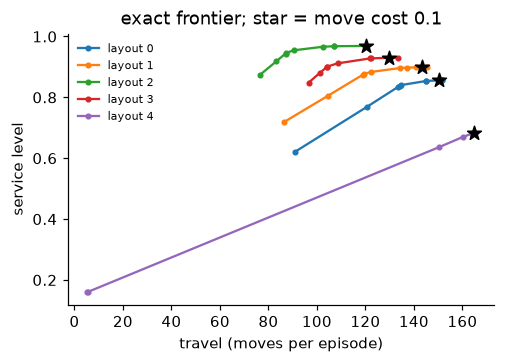

layout 0: cost 0.1 -> 0.856 / 150 moves;  cost 0.5 -> 0.854 / 145 moves
layout 1: cost 0.1 -> 0.899 / 143 moves;  cost 0.5 -> 0.898 / 137 moves
layout 2: cost 0.1 -> 0.969 / 120 moves;  cost 0.5 -> 0.968 / 107 moves
layout 3: cost 0.1 -> 0.930 / 130 moves;  cost 0.5 -> 0.928 / 122 moves
layout 4: cost 0.1 -> 0.683 / 165 moves;  cost 0.5 -> 0.683 / 165 moves


In [8]:
fig, ax = plt.subplots(figsize=(5, 3.2))
for d in audit[:5]:
    fr = d["frontier"]
    ax.plot([f["distance"] for f in fr], [f["service_level"] for f in fr], marker="o", ms=3, label=f"layout {d['layout']}")
    o = d["rewards"]["objective"]
    ax.scatter(o["distance"], o["service_level"], marker="*", s=90, color="black", zorder=5)
ax.set_xlabel("travel (moves per episode)"); ax.set_ylabel("service level"); ax.legend(frameon=False, fontsize=7)
ax.set_title("exact frontier; star = move cost 0.1"); plt.show()
for d in audit[:5]:
    fr = {f["move_cost"]: f for f in d["frontier"]}
    print(f"layout {d['layout']}: cost 0.1 -> {fr[0.1]['service_level']:.3f} / {fr[0.1]['distance']:.0f} moves;"
          f"  cost 0.5 -> {fr[0.5]['service_level']:.3f} / {fr[0.5]['distance']:.0f} moves")

At 0.1 per move the optimum sits at the flat end of the frontier. Raising the price to 0.5 removes 3--11% of the travel on four of these five layouts for at most 0.2 points of service; layout 4, which is limited by travel capacity, does not change. If robot energy matters to the store, the current weight undervalues it.

## 2.5 A bound from travel time alone

Every unit sold from shelf $i$ has to be carried there. A reload, trip, restock and return carrying two units takes $2d_i + 2$ steps, so each delivered unit costs at least $d_i + 1$ robot steps (splitting a load between shelves is never cheaper per unit). Expected sales are at least $pT\,SL_i$ and cannot exceed the initial three units plus deliveries, so

$$\sum_i (d_i + 1)\max(0,\; pT\,SL_i - 3) \le T + d_{max} + 2 .$$

Maximising mean $SL_i$ under this constraint is a small linear program (`service_bound` in `run_dp_audit.py`).

In [9]:
for d in audit:
    o = d["rewards"]["objective"]
    print(f"layout {d['layout']} shelves {d['shelves']}: optimum {o['service_level']:.3f}   bound {d['service_bound']:.3f}")

layout 0 shelves [[3, 0], [2, 2]]: optimum 0.856   bound 1.000
layout 1 shelves [[1, 3], [2, 0]]: optimum 0.899   bound 1.000
layout 2 shelves [[1, 0], [3, 0]]: optimum 0.969   bound 1.000
layout 3 shelves [[0, 2], [3, 0]]: optimum 0.930   bound 1.000
layout 4 shelves [[2, 3], [3, 3]]: optimum 0.683   bound 0.807
layout 5 shelves [[3, 1], [2, 2]]: optimum 0.807   bound 0.983
layout 6 shelves [[1, 3], [2, 1]]: optimum 0.856   bound 1.000
layout 7 shelves [[3, 2], [2, 2]]: optimum 0.769   bound 0.917
layout 8 shelves [[1, 1], [2, 3]]: optimum 0.868   bound 1.000
layout 9 shelves [[1, 2], [3, 2]]: optimum 0.816   bound 0.990


The bound only binds when both shelves are far from the depot (layouts 4, 5, 7, 9). Layout 4 is the clearest case: no policy can keep its shelves stocked more than about 81% of the time, and the optimum achieves 68%. Elsewhere the limit is the randomness of demand, not travel capacity.